In [8]:
!git clone https://github.com/XingpengSang/5001groupproject.git /content/5001groupproject

fatal: destination path '/content/5001groupproject' already exists and is not an empty directory.


In [9]:
%cd /content/5001groupproject
!ls -lh Dataset/data.csv

/content/5001groupproject
-rw-r--r-- 1 root root 29M Nov 17 04:20 Dataset/data.csv


In [10]:
from pathlib import Path
from google.colab import files

project = Path("/content/5001groupproject")
uploaded = files.upload()
expected = ("02_data_preprocessing.py", "03_model_training.py")

for name in expected:
    if name not in uploaded:
        raise ValueError(f"请重新运行这一格，并选择 {name}")

for name in expected:
    (project / "src" / name).write_bytes(uploaded[name])
    print(f"已放入 src/{name}")

Saving 02_data_preprocessing.py to 02_data_preprocessing (1).py
Saving 03_model_training.py to 03_model_training (1).py


ValueError: 请重新运行这一格，并选择 02_data_preprocessing.py

In [ ]:
%cd /content/5001groupproject

import subprocess
import sys
import pandas as pd

subprocess.run([sys.executable, "src/02_data_preprocessing.py"], check=True)
subprocess.run([sys.executable, "src/03_model_training.py"], check=True)

results = pd.read_csv("output/model_evaluation_results.csv")
display(results.sort_values(["Feature_Group", "RMSE"]))

In [ ]:
from pathlib import Path
import subprocess
import sys

from google.colab import files
from IPython.display import Image, display

project = Path("/content/5001groupproject")
name = "04_ols_inference.py"
uploaded = files.upload()
(project / "src" / name).write_bytes(uploaded[name])

subprocess.run([sys.executable, f"src/{name}"], cwd=project, check=True)

for path in sorted((project / "output" / "figures").glob("*.png")):
    display(Image(filename=str(path)))

| 图 | 看什么 | 对应的统计概念 |
|---|---|---|
| **测试集 RMSE** | 看「仅音频」「仅年份」「音频＋年份」三根柱子。已有结果是 **16.15、10.94、10.73**，虚线是均值基准。 | 在同一个测试集上比较模型，衡量增加变量带来的预测收益。 |
| **发行年份与热度** | 看各年份的热度中位数和中间 50% 的范围，观察年份模型表现好的原因。 | 探索性分析。阴影表示歌曲之间的热度分布，用的是第 25 到第 75 百分位数。 |
| **控制年份前后的音频系数** | 每个特征有两个点。比如 `energy` 的点如果加年份后靠近 0，说明控制年份后，能量与热度的条件关联变弱。 | 把不同单位的特征换算到「增加 1 个标准差」，纵向比较各特征。横线是 **95% HC3 稳健置信区间**，系数表示回归中的关联。 |

,n,mean_residual,rmse
decade,,,
1920,1023,6.40,7.69
1930,1917,2.15,6.62
1940,3134,-5.51,8.04
1950,3936,-4.39,11.08
1960,3963,3.49,11.78
1970,3931,4.48,12.04
1980,3916,-0.14,10.49
1990,3950,-0.15,9.60
2000,3975,-1.43,8.95


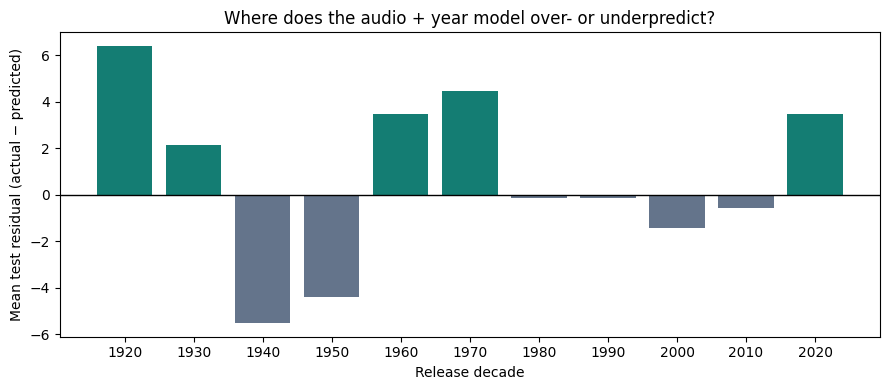

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

output = Path("/content/5001groupproject/output")

tracks = pd.read_csv(output / "spotify_modeling_data.csv")
predictions = pd.read_csv(output / "model_test_predictions.csv")
test = predictions.loc[
    predictions["Feature_Group"].eq("Group_B_Audio_Year")
].copy()

# Original_Index 是训练脚本保存的建模数据行号。
test["year"] = tracks.iloc[test["Original_Index"].to_numpy()]["year"].to_numpy()
test["decade"] = (test["year"] // 10 * 10).astype(int)
test["residual"] = test["Actual_Popularity"] - test["OLS"]
test["squared_error"] = test["residual"] ** 2

summary = test.groupby("decade").agg(
    n=("residual", "size"),
    mean_residual=("residual", "mean"),
    mse=("squared_error", "mean"),
)
summary["rmse"] = summary.pop("mse") ** 0.5
display(summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
colors = summary["mean_residual"].map(
    lambda value: "#147d73" if value >= 0 else "#64748b"
)
ax.bar(summary.index.astype(str), summary["mean_residual"], color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set(
    title="Where does the audio + year model over- or underpredict?",
    xlabel="Release decade",
    ylabel="Mean test residual (actual − predicted)",
)
fig.tight_layout()

figures = output / "figures"
figures.mkdir(exist_ok=True)
fig.savefig(figures / "04_residuals_by_decade.png", dpi=300)
fig.savefig(figures / "04_residuals_by_decade.svg", bbox_inches="tight")
plt.show()

In [14]:
from google.colab import files
files.download("/content/5001groupproject/output/figures/04_residuals_by_decade.svg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from pathlib import Path
from zipfile import ZipFile

from google.colab import files

project = Path("/content/5001groupproject")
paths = [
    project / "src/02_data_preprocessing.py",
    project / "src/03_model_training.py",
    project / "src/04_ols_inference.py",
    project / "output/model_evaluation_results.csv",
    *sorted((project / "output/figures").glob("*.png")),
    *sorted((project / "output/figures").glob("*.svg")),
]

bundle = Path("/content/spotify-analysis.zip")
with ZipFile(bundle, "w") as archive:
    for path in paths:
        archive.write(path, path.relative_to(project))

files.download(str(bundle))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from pathlib import Path
from shutil import copy2
import subprocess
import sys

from google.colab import files

project = Path("/content/5001groupproject")
src = project / "src"

if not src.is_dir():
    raise FileNotFoundError(f"找不到项目目录：{src}")

for name in ("02_data_preprocessing", "03_model_training"):
    matches = list(Path("/content").rglob(f"{name} (1).py"))
    if not matches:
        raise FileNotFoundError(f"找不到刚上传的 {name} (1).py")
    latest = max(matches, key=lambda path: path.stat().st_mtime)
    copy2(latest, src / f"{name}.py")
    print(f"已恢复 src/{name}.py")

print("请只上传新版 04_ols_inference.py")
uploaded = files.upload()
if len(uploaded) != 1 or not next(iter(uploaded)).startswith("04_ols_inference"):
    raise ValueError("请选择一个文件：04_ols_inference.py")
(src / "04_ols_inference.py").write_bytes(next(iter(uploaded.values())))

for name in (
    "02_data_preprocessing.py",
    "03_model_training.py",
    "04_ols_inference.py",
):
    print(f"正在运行 {name}", flush=True)
    subprocess.run([sys.executable, f"src/{name}"], cwd=project, check=True)

print("结果表和前三张图已恢复。")

已恢复 src/02_data_preprocessing.py
已恢复 src/03_model_training.py
请只上传新版 04_ols_inference.py


Saving 04_ols_inference.py to 04_ols_inference (2).py
正在运行 02_data_preprocessing.py
正在运行 03_model_training.py
正在运行 04_ols_inference.py
结果表和前三张图已恢复。
